# bench-aitextdetect — AI-Generated Text Detection Benchmark

This notebook benchmarks **LLM fine-tuning** (QLoRA) and classical ML baselines on
the task of distinguishing **human-written** from **machine-generated** text.

**Dataset**: [MAGE](https://huggingface.co/datasets/yaful/MAGE) (ACL 2024) —
447,674 samples across 10 source datasets and 27 generators, including GPT-3.5, GPT-4,
LLaMA, etc.).  Binary labels: `0 = machine-generated`, `1 = human-written`.

**Models benchmarked**:

| Category | Model | Size | Method |
|----------|-------|------|--------|
| Baselines | TF-IDF + LogReg / RF / XGBoost / LightGBM | — | Classical ML on n-gram features |
| Encoder (QLoRA) | [ModernBERT-base](https://huggingface.co/answerdotai/ModernBERT-base) | 149 M | 4-bit NF4, LoRA r=16, 8192-token context |
| Encoder (QLoRA) | [ModernBERT-large](https://huggingface.co/answerdotai/ModernBERT-large) | 395 M | 4-bit NF4, LoRA r=16, 8192-token context |
| Causal LM (QLoRA) | [Qwen3.5-4B-Base](https://huggingface.co/Qwen/Qwen3.5-4B-Base) | 4 B | 4-bit NF4, LoRA r=16 |
| Causal LM (QLoRA) | [Gemma-4-E4B](https://huggingface.co/google/gemma-4-E4B) | 4.5 B effective / 8 B total | 4-bit NF4, LoRA r=16 |
| Causal LM (QLoRA) | [Nanbeige4.2-3B](https://huggingface.co/Nanbeige/Nanbeige4.2-3B) | 4 B total / 3 B non-embedding | 4-bit NF4, LoRA r=16 |
| Hybrid LM (QLoRA) | [LFM2.5-2.6B](https://huggingface.co/LiquidAI/LFM2.5-2.6B) | 2.6 B | 4-bit NF4, LoRA r=16 |

**Evaluation**:
- In-domain: MAGE test set + two OOD splits (`test_ood_set_gpt`, `test_ood_set_gpt_para`)
- Cross-dataset: [artem9k/ai-text-detection-pile](https://huggingface.co/datasets/artem9k/ai-text-detection-pile) — multi-generator robustness
- External OOD: [IntelLabs/AI-Peer-Review-Detection-Benchmark](https://huggingface.co/datasets/IntelLabs/AI-Peer-Review-Detection-Benchmark) — newer generators and a held-out domain

The QLoRA profile below is tuned for a **32 GB CUDA GPU**. Classical baselines run on CPU.

## 1. Environment Setup

In [1]:
import os
from pathlib import Path

candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next((path for path in candidates if (path / "ai_content_detector").is_dir() and (path / "pyproject.toml").is_file()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook from an ai-content-robustness checkout after installing its dependencies")
os.chdir(repo_root)
print(f"Using checkout: {repo_root}")


Using checkout: /lustre/fswork/projects/rech/mbm/ual37ci/bench_research_ml_project/split-repos/ai-content-robustness


In [2]:
print(f"Working directory: {Path.cwd()}")


Working directory: /lustre/fswork/projects/rech/mbm/ual37ci/bench_research_ml_project/split-repos/ai-content-robustness


## 2. Imports and Deterministic Utilities

In [3]:
import os, random, logging
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from ml_pipeline.pipelines_torch.models import (
    CLASSIFICATION_MODEL_REGISTRY,
    HuggingFaceQLoRAWrapper,
)
from ml_pipeline.pipelines_torch.benchmark import BenchmarkRunner
from ml_pipeline.pipelines_torch.base import GeneralPipeline, GeneralPipelineSklearn, SimplePredictor
from ml_pipeline.utils.metrics import METRIC_REGISTRY
from ml_pipeline.utils.utils import save_model, save_metrics, model_exists, load_model_by_name

logging.basicConfig(level=logging.INFO)
logger = logging.getLogger(__name__)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Device: cuda
GPU: NVIDIA H100 80GB HBM3


## 3. Download and Explore the MAGE Dataset

[MAGE](https://huggingface.co/datasets/yaful/MAGE) (ACL 2024) provides:
- **train** (319 k), **valid** (57 k), **test** (61 k) — standard splits
- **test_ood_set_gpt** — out-of-distribution GPT-generated texts
- **test_ood_set_gpt_para** — paraphrased GPT texts (harder to detect)

Columns: `text`, `label` (0 = machine, 1 = human).

MAGE is a strong broad training source for this project because it deliberately covers
multiple domains, generators, prompting modes, and difficult OOD splits. It is not a
complete proxy for deployment: its corpus was assembled in 2023, current frontier
generators are absent, provenance can correlate with labels, and the 10 k training subset
used below covers only a fraction of its 319 k training rows. The external Pile and OOD
peer-review evaluations are therefore required, not optional validation extras.

In [4]:
from datasets import load_dataset

ds = load_dataset("yaful/MAGE")
print(ds)

# Preview
for split_name in ds:
    print(f"\n--- {split_name} ({len(ds[split_name]):,} rows) ---")
    print(ds[split_name][0])

Using the latest cached version of the dataset since yaful/MAGE couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /lustre/fswork/projects/rech/mbm/ual37ci/.cache/huggingface/datasets/yaful___mage/default/0.0.0/342663f0a2b775455c023f5d36a1341ff0ec5402 (last modified on Wed Oct 14 18:21:09 2026).


DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 319071
    })
    validation: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 56792
    })
    test: Dataset({
        features: ['text', 'label', 'src'],
        num_rows: 60743
    })
})

--- train (319,071 rows) ---
{'text': "White girls very rarely date Asian men. Even in Asia white men are much more popular than Asian men. Even though an Asian guy may have a preference for white girls he doesn't have much of a chance with one so he should instead pursue a non-White girl. Asian guys are penalized by their looks because I don't see them as being significantly less social, athletic, intelligent, wealthy, etc. Facial looks are genetic and cannot be changed easily. Having a fit body helps but not nearly as much as for white or black guys. I wish it weren't true. EDIT: Basically I'm saying Asian men are at a significant disadvantage in the dating scene especially if t

In [5]:
# Convert to DataFrames for easier manipulation
df_train = ds["train"].to_pandas()
df_val = ds["validation"].to_pandas()
df_test = ds["test"].to_pandas()

# OOD test sets (may have different column names)
ood_splits = {k: ds[k].to_pandas() for k in ds if k not in ("train", "validation", "test")}
print(f"OOD splits available: {list(ood_splits.keys())}")

# Basic stats
print(f"\nTrain: {len(df_train):,} | Val: {len(df_val):,} | Test: {len(df_test):,}")
print(f"\nTrain label distribution:\n{df_train['label'].value_counts()}")
print(f"\nTest label distribution:\n{df_test['label'].value_counts()}")

# Text length distribution
df_train["text_len"] = df_train["text"].str.len()
print(f"\nText length stats (train):\n{df_train['text_len'].describe()}")

OOD splits available: []

Train: 319,071 | Val: 56,792 | Test: 60,743

Train label distribution:
label
0    225753
1     93318
Name: count, dtype: int64

Test label distribution:
label
0    30478
1    30265
Name: count, dtype: int64



Text length stats (train):
count    319071.000000
mean       1228.018334
std        1421.562883
min          21.000000
25%         311.000000
50%         675.000000
75%        1495.000000
max       59509.000000
Name: text_len, dtype: float64


In [6]:
# Subsample for tractable training (full dataset is 319k — too slow for QLoRA grid search)
# Use 10k train, 2k val, full test sets
TRAIN_SIZE = 10_000
VAL_SIZE = 2_000

df_train_sub = df_train.groupby("label", group_keys=False).apply(
    lambda g: g.sample(n=TRAIN_SIZE // 2, random_state=SEED)
).reset_index(drop=True)

df_val_sub = df_val.groupby("label", group_keys=False).apply(
    lambda g: g.sample(n=min(VAL_SIZE // 2, len(g)), random_state=SEED)
).reset_index(drop=True)

print(f"Subsampled train: {len(df_train_sub):,} | val: {len(df_val_sub):,}")
print(f"Train labels:\n{df_train_sub['label'].value_counts()}")

X_train = df_train_sub["text"].tolist()
y_train = df_train_sub["label"].values

X_val = df_val_sub["text"].tolist()
y_val = df_val_sub["label"].values

X_test = df_test["text"].tolist()
y_test = df_test["label"].values

Subsampled train: 10,000 | val: 2,000
Train labels:
label
0    5000
1    5000
Name: count, dtype: int64


/tmp/ipykernel_2937533/3251194652.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_train_sub = df_train.groupby("label", group_keys=False).apply(
/tmp/ipykernel_2937533/3251194652.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_val_sub = df_val.groupby("label", group_keys=False).apply(


## 4. Classical ML Baselines (TF-IDF)

TF-IDF vectorisation + four classifiers from the repo registry.
These run on CPU and serve as strong baselines — TF-IDF frequently
performs surprisingly well on stylistic detection tasks.

In [7]:
# Fit TF-IDF on training texts
tfidf = TfidfVectorizer(max_features=50_000, sublinear_tf=True, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train).toarray().astype(np.float32)
X_val_tfidf = tfidf.transform(X_val).toarray().astype(np.float32)
X_test_tfidf = tfidf.transform(X_test).toarray().astype(np.float32)

print(f"TF-IDF features: {X_train_tfidf.shape[1]:,}")

TF-IDF features: 50,000


In [8]:
from ml_pipeline.pipelines_torch.models import (
    SklearnRandomForestClassifierWrapper,
    XGBoostClassifierWrapper,
    LightGBMClassifierWrapper,
)

baseline_configs = [
    {
        "name": "tfidf_logreg",
        "class": lambda input_dim, num_classes=2: LogisticRegression(
            max_iter=1000, C=1.0, solver="lbfgs", random_state=SEED
        ),
        "params": {"input_dim": X_train_tfidf.shape[1], "num_classes": 2},
    },
    {
        "name": "tfidf_random_forest",
        "class": SklearnRandomForestClassifierWrapper,
        "params": {"input_dim": X_train_tfidf.shape[1], "num_classes": 2},
    },
    {
        "name": "tfidf_xgboost",
        "class": XGBoostClassifierWrapper,
        "params": {"input_dim": X_train_tfidf.shape[1], "num_classes": 2},
    },
    {
        "name": "tfidf_lightgbm",
        "class": LightGBMClassifierWrapper,
        "params": {"input_dim": X_train_tfidf.shape[1], "num_classes": 2},
    },
]

# Combine train+val for sklearn (no early stopping needed)
X_baseline = np.vstack([X_train_tfidf, X_val_tfidf])
y_baseline = np.concatenate([y_train, y_val])

runner_baseline = BenchmarkRunner(
    model_configs=baseline_configs,
    augmentations=[None],
    task_type="classification",
    device="cpu",
    epochs=1,  # sklearn models ignore this
    batch_size=32,
    early_stopping=None,
    use_class_weights=True,
    use_kfold=True,
    k_folds=3,
    use_wandb=True,
    path_start="bench_aitextdetect",
    random_state=SEED,
)
runner_baseline.run(X_baseline, y_baseline)

Models:   0%|          | 0/4 [00:00<?, ?it/s]

Augmentations:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:ml_pipeline.pipelines_torch.benchmark:Skipping tfidf_logreg | none (checkpoint already exists)


Augmentations: 100%|██████████| 1/1 [00:00<00:00,  4.59it/s]

Models:  25%|██▌       | 1/4 [00:00<00:00,  4.54it/s]

...

INFO:ml_pipeline.pipelines_torch.benchmark:Skipping tfidf_xgboost | none (checkpoint already exists)


Augmentations:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:ml_pipeline.pipelines_torch.benchmark:Skipping tfidf_lightgbm | none (checkpoint already exists)


Models: 100%|██████████| 4/4 [00:00<00:00, 11.85it/s]

Models: 100%|██████████| 4/4 [00:00<00:00, 10.57it/s]

## 5. QLoRA Fine-Tuning

This notebook uses a **32 GB VRAM** QLoRA profile. Six models are benchmarked
with the repo's `HuggingFaceQLoRAWrapper` (4-bit NF4 quantization, LoRA rank 16),
each in its own `BenchmarkRunner`:

| Model | Type | Params | Batch size | Grad accum | Effective batch | Max tokens | Epochs | Notes |
|-------|------|--------|-----------:|-----------:|----------------:|-----------:|-------:|-------|
| ModernBERT-base | Encoder | 149 M | 16 | 1 | 16 | 2048 | 2 | More throughput while retaining longer-document signal |
| ModernBERT-large | Encoder | 395 M | 8 | 2 | 16 | 2048 | 2 | Strong encoder setting that still leaves memory headroom |
| Qwen3.5-4B-Base | Causal LM | 4 B | 4 | 4 | 16 | 1024 | 2 | Causal activations dominate memory, so context is capped lower |
| Gemma-4-E4B | Causal LM | 4.5 B effective / 8 B total | 4 | 4 | 16 | 1024 | 2 | Multimodal backbone, text-only classification path |
| Nanbeige4.2-3B | Causal LM | 4 B total / 3 B non-embedding | 4 | 4 | 16 | 1024 | 2 | Post-trained checkpoint requested for comparison |
| LFM2.5-2.6B | Hybrid LM | 2.6 B | 4 | 4 | 16 | 1024 | 2 | Post-trained hybrid convolution-attention checkpoint |

> **32 GB GPU memory profile**
> - The quantized model weights fit comfortably; activation memory from batch size and sequence
>   length is the real limiter during fine-tuning.
> - Encoders get a 2048-token training context because ModernBERT's attention pattern is cheaper
>   for long documents.
> - Causal/hybrid LMs stay at 1024 tokens with gradient checkpointing; raise to 2048 only after
>   confirming your local run has memory headroom.
> - Gemma-4-E4B uses the base checkpoint. The wrapper attaches a trainable classification
>   head to the text-only path; no chat template or instruction-tuned checkpoint is used.

**Wrapper changes for causal / hybrid LLMs** (in `pipelines_torch/models.py`):
- Auto-detects causal vs encoder architecture -> sets `padding_side="left"` for causal LMs
- Sets `pad_token = eos_token` when missing; propagates `pad_token_id` into `model.config`
- Auto-detects head name (`"classifier"` vs `"score"`) for `modules_to_save`
- Falls back from `target_modules="all-linear"` to explicit attention+MLP modules for MoE/SSM layers
- Uses `gradient_checkpointing_kwargs={"use_reentrant": False}` for causal/hybrid LMs
- Accepts a wrapper-level `max_seq_length` so each notebook config controls token budget


In [9]:
QLORA_VRAM_PROFILE = "32gb"

QLORA_CONFIGS = {
    "qlora_modernbert_base": {
        "hf_model": "answerdotai/ModernBERT-base",
        "batch_size": 16,
        "epochs": 2,
        "lr": 1e-4,
        "gradient_accumulation_steps": 1,
        "max_seq_length": 2048,
    },
    "qlora_modernbert_large": {
        "hf_model": "answerdotai/ModernBERT-large",
        "batch_size": 8,
        "epochs": 2,
        "lr": 1e-4,
        "gradient_accumulation_steps": 2,
        "max_seq_length": 2048,
    },
    "qlora_qwen35_4b": {
        "hf_model": "Qwen/Qwen3.5-4B-Base",
        "batch_size": 4,
        "epochs": 2,
        "lr": 5e-5,
        "gradient_accumulation_steps": 4,
        "max_seq_length": 1024,
    },
    "qlora_gemma4_e4b": {
        "hf_model": "google/gemma-4-E4B",  # Gemma 4 base checkpoint with a custom sequence-classification head
        "batch_size": 4,
        "epochs": 2,
        "lr": 5e-5,
        "gradient_accumulation_steps": 4,
        "max_seq_length": 1024,
    },
    "qlora_nanbeige42_3b": {
        "hf_model": "Nanbeige/Nanbeige4.2-3B",
        "batch_size": 4,
        "epochs": 2,
        "lr": 5e-5,
        "gradient_accumulation_steps": 4,
        "max_seq_length": 1024,
    },
    "qlora_lfm25_26b": {
        "hf_model": "LiquidAI/LFM2.5-2.6B",
        "batch_size": 4,
        "epochs": 2,
        "lr": 5e-5,
        "gradient_accumulation_steps": 4,
        "max_seq_length": 1024,
    },
}

ALL_QLORA_MODELS = {name: cfg["hf_model"] for name, cfg in QLORA_CONFIGS.items()}
print(f"QLoRA VRAM profile: {QLORA_VRAM_PROFILE}")
print("QLoRA models:", list(ALL_QLORA_MODELS.keys()))


QLoRA VRAM profile: 32gb
QLoRA models: ['qlora_modernbert_base', 'qlora_modernbert_large', 'qlora_qwen35_4b', 'qlora_gemma4_e4b', 'qlora_nanbeige42_3b', 'qlora_lfm25_26b']


In [10]:
def run_qlora_model(name, cfg, X, y, path_start="bench_aitextdetect"):
    """Run a single QLoRA model through BenchmarkRunner with its own GPU-budget settings."""
    hf_model = cfg["hf_model"]
    grad_accum = cfg.get("gradient_accumulation_steps", 2)
    max_seq_length = cfg.get("max_seq_length", 512)

    model_config = [{
        "name": name,
        "class": lambda model_name=hf_model, ga=grad_accum, msl=max_seq_length, **kw: HuggingFaceQLoRAWrapper(
            model_name=model_name,
            num_labels=2,
            task_type="classification",
            device=DEVICE,
            gradient_accumulation_steps=ga,
            max_seq_length=msl,
        ),
        "params": {},
    }]

    runner = BenchmarkRunner(
        model_configs=model_config,
        augmentations=[None],
        task_type="classification",
        device=DEVICE,
        epochs={name: cfg["epochs"]},
        batch_size=cfg["batch_size"],
        early_stopping=None,
        use_class_weights=False,
        use_kfold=False,
        learning_rate=cfg["lr"],
        use_wandb=True,
        path_start=path_start,
        random_state=SEED,
    )
    runner.run(np.array(X), y)
    print(f"  Done: {name}")


for model_name, model_cfg in QLORA_CONFIGS.items():
    effective_batch = model_cfg["batch_size"] * model_cfg["gradient_accumulation_steps"]
    print(f"\n{'='*60}")
    print(f"Training: {model_name}  ({model_cfg['hf_model']})")
    print(
        f"  batch={model_cfg['batch_size']}  epochs={model_cfg['epochs']}"
        f"  grad_accum={model_cfg['gradient_accumulation_steps']}  effective_batch={effective_batch}"
        f"  max_seq={model_cfg['max_seq_length']}  lr={model_cfg['lr']}"
    )
    print('='*60)
    run_qlora_model(model_name, model_cfg, X_train, y_train)



Training: qlora_modernbert_base  (answerdotai/ModernBERT-base)
  batch=16  epochs=2  grad_accum=1  effective_batch=16  max_seq=2048  lr=0.0001


Models:   0%|          | 0/1 [00:00<?, ?it/s]

Augmentations:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:ml_pipeline.pipelines_torch.benchmark:Skipping qlora_modernbert_base | none (checkpoint already exists)


Models: 100%|██████████| 1/1 [00:00<00:00, 11.32it/s]

...

Models:   0%|          | 0/1 [00:00<?, ?it/s]

Augmentations:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:ml_pipeline.pipelines_torch.benchmark:Skipping qlora_lfm25_26b | none (checkpoint already exists)


Models: 100%|██████████| 1/1 [00:00<00:00, 24.34it/s]

  Done: qlora_lfm25_26b


## 6. Evaluate All Models on Test Set

Score every trained model on the held-out MAGE test split using the shared
metric registry (accuracy, F1, precision, recall, ROC-AUC, PR-AUC).

In [11]:
METRIC_MAP = {
    "accuracy": "accuracy",
    "f1_macro": "f1",
    "precision_macro": "precision",
    "recall_macro": "recall",
    "roc_auc": "roc_auc",
    "pr_auc": "pr_auc",
}


def evaluate_sklearn_models(model_names, X_eval, y_eval, tfidf_vectorizer):
    """Evaluate sklearn-based models that need TF-IDF features."""
    records = []
    X_tfidf = tfidf_vectorizer.transform(X_eval).toarray().astype(np.float32)

    for name, cfg in zip(model_names, baseline_configs):
        try:
            model_class = cfg["class"]
            model = load_model_by_name(
                model_class, name, cfg["params"],
                path_start="bench_aitextdetect"
            )
        except FileNotFoundError:
            print(f"  Skipping {name}: checkpoint not found")
            continue

        if hasattr(model, "predict_proba"):
            probs = model.predict_proba(X_tfidf)
            if probs.ndim == 1:
                probs = np.column_stack([1 - probs, probs])
        else:
            preds = model.predict(X_tfidf)
            probs = np.zeros((len(preds), 2))
            probs[np.arange(len(preds)), preds.astype(int)] = 1.0

        scores = {
            label: float(METRIC_REGISTRY[key](y_eval, probs))
            for label, key in METRIC_MAP.items()
        }
        records.append({"model": name, **scores})
        print(f"  {name}: acc={scores['accuracy']:.4f} f1={scores['f1_macro']:.4f}")

    return pd.DataFrame.from_records(records)


def evaluate_qlora_models(qlora_model_dict, X_eval, y_eval):
    """Evaluate QLoRA fine-tuned models.

    qlora_model_dict: {name: hf_model_id}, e.g. ALL_QLORA_MODELS
    """
    records = []

    for name, hf_model in qlora_model_dict.items():
        try:
            model_class = lambda model_name=hf_model, **kw: HuggingFaceQLoRAWrapper(
                model_name=model_name, num_labels=2,
                task_type="classification", device=DEVICE,
            )
            model = load_model_by_name(
                model_class, name, {},
                path_start="bench_aitextdetect"
            )
        except FileNotFoundError:
            print(f"  Skipping {name}: checkpoint not found")
            continue

        probs = model.predict_proba(X_eval)
        scores = {
            label: float(METRIC_REGISTRY[key](y_eval, probs))
            for label, key in METRIC_MAP.items()
        }
        records.append({"model": name, **scores})
        print(f"  {name}: acc={scores['accuracy']:.4f} f1={scores['f1_macro']:.4f}")

    return pd.DataFrame.from_records(records)

In [12]:
print("=== Baseline (TF-IDF) models on MAGE test set ===")
baseline_names = [cfg["name"] for cfg in baseline_configs]
df_baseline_results = evaluate_sklearn_models(baseline_names, X_test, y_test, tfidf)

print("\n=== QLoRA models on MAGE test set ===")
df_qlora_results = evaluate_qlora_models(ALL_QLORA_MODELS, X_test, y_test)

df_all_results = pd.concat([df_baseline_results, df_qlora_results], ignore_index=True)
df_all_results = df_all_results.sort_values("f1_macro", ascending=False).reset_index(drop=True)
df_all_results

=== Baseline (TF-IDF) models on MAGE test set ===


  tfidf_logreg: acc=0.6596 f1=0.6588


  tfidf_random_forest: acc=0.6691 f1=0.6687


  tfidf_xgboost: acc=0.6836 f1=0.6836


  tfidf_lightgbm: acc=0.6994 f1=0.6994

=== QLoRA models on MAGE test set ===


...

  Cached qlora_lfm25_26b: 58880/60743


  Cached qlora_lfm25_26b: 60160/60743


  Cached qlora_lfm25_26b: 60743/60743


  qlora_lfm25_26b: acc=0.9061 f1=0.9061


,model,accuracy,f1_macro,precision_macro,recall_macro,roc_auc,pr_auc
0,qlora_qwen35_4b,0.923613,0.923610,0.923631,0.923602,0.977596,0.975169
1,qlora_gemma4_e4b,0.907463,0.907461,0.907536,0.907488,0.965962,0.961725
2,qlora_lfm25_26b,0.906129,0.906127,0.906224,0.906157,0.962790,0.957219
3,qlora_modernbert_large,0.817510,0.815330,0.832326,0.817139,0.929095,0.921587
4,qlora_modernbert_base,0.791960,0.790814,0.797929,0.791710,0.896412,0.888034
5,qlora_nanbeige42_3b,0.700377,0.700377,0.700381,0.700383,0.779907,0.773262
6,tfidf_lightgbm,0.699406,0.699383,0.699420,0.699384,0.781327,0.772604
7,tfidf_xgboost,0.683585,0.683562,0.683595,0.683563,0.762481,0.751873
8,tfidf_random_forest,0.669131,0.668710,0.669792,0.669014,0.738953,0.709537
9,tfidf_logreg,0.659648,0.658763,0.661033,0.659478,0.729543,0.710352


## 7. Out-of-Distribution (OOD) Generalisation

The MAGE dataset ships with two OOD test sets to evaluate robustness:
- **test_ood_set_gpt** — texts from GPT models not seen during training
- **test_ood_set_gpt_para** — GPT texts that have been paraphrased (hardest setting)

This mirrors the cross-dataset evaluation done in `bench-imai` for images.

In [13]:
ood_results = {}

for ood_name, ood_df in ood_splits.items():
    print(f"\n=== OOD: {ood_name} ({len(ood_df):,} samples) ===")
    X_ood = ood_df["text"].tolist()
    y_ood = ood_df["label"].values
    print(f"Label distribution: {dict(zip(*np.unique(y_ood, return_counts=True)))}")

    print("\n--- Baselines ---")
    df_bl = evaluate_sklearn_models(baseline_names, X_ood, y_ood, tfidf)

    print("\n--- QLoRA ---")
    df_ql = evaluate_qlora_models(ALL_QLORA_MODELS, X_ood, y_ood)

    ood_combined = pd.concat([df_bl, df_ql], ignore_index=True)
    ood_combined["dataset"] = ood_name
    ood_results[ood_name] = ood_combined

if ood_results:
    df_ood_all = pd.concat(ood_results.values(), ignore_index=True)
    df_ood_all

## 8. Cross-Dataset Evaluation — AI Text Detection Pile

[artem9k/ai-text-detection-pile](https://huggingface.co/datasets/artem9k/ai-text-detection-pile)
is a large-scale, multi-generator corpus covering GPT-2, GPT-3, GPT-J, and ChatGPT outputs
mixed with human text.  It is a **different distribution** from MAGE — different domains,
different generation methods — so performance here measures genuine cross-dataset generalisation.

All models are evaluated **zero-shot** (no retraining): we apply the MAGE-trained checkpoints
directly to this dataset.  We subsample to 5 k samples to keep inference time tractable.

In [14]:
PILE_EVAL_SIZE = 5_000

ds_pile = load_dataset("artem9k/ai-text-detection-pile", split="train")
df_pile = ds_pile.to_pandas()

print(f"AI Text Detection Pile — {len(df_pile):,} rows")
print("Columns:", df_pile.columns.tolist())
print(df_pile.head(3))

Using the latest cached version of the dataset since artem9k/ai-text-detection-pile couldn't be found on the Hugging Face Hub (offline mode is enabled).


Found the latest cached dataset configuration 'default' at /lustre/fswork/projects/rech/mbm/ual37ci/.cache/huggingface/datasets/artem9k___ai-text-detection-pile/default/0.0.0/aaaabe386a88dafa8de1fa42c0fbee0ad5d48b6a (last modified on Wed Oct 14 18:33:43 2026).


AI Text Detection Pile — 1,392,522 rows
Columns: ['source', 'id', 'text']
  source  id                                               text
0  human   0  12 Years a Slave: An Analysis of the Film Essa...
1  human   1  20+ Social Media Post Ideas to Radically Simpl...
2  human   2  2022 Russian Invasion of Ukraine in Global Med...


In [15]:
# Normalise columns: the current pile schema is ['source', 'id', 'text'], where
# 'source' is a string ('human' or 'ai') rather than a boolean/int flag.
# Remap to the same 'text' / 'label' convention as MAGE (0=machine, 1=human)
text_col = next(c for c in df_pile.columns if c.lower() == "text")
label_col = next(
    (c for c in df_pile.columns if c.lower() in ("is_generated", "label", "generated", "ai")),
    None
)
source_col = next((c for c in df_pile.columns if c.lower() == "source"), None)

df_pile = df_pile.rename(columns={text_col: "text"})

if label_col and label_col != "label":
    # is_generated=1 means machine, so label = 1 - is_generated (human=1 like MAGE)
    df_pile["label"] = 1 - df_pile[label_col].astype(int)
elif label_col == "label":
    df_pile["label"] = df_pile["label"].astype(int)
elif source_col:
    # source names the generator ('human' vs a model name); human=1 like MAGE
    df_pile["label"] = (df_pile[source_col].astype(str).str.lower() == "human").astype(int)
else:
    raise ValueError(f"Cannot find label column in: {df_pile.columns.tolist()}")

print(f"Label distribution:\n{df_pile['label'].value_counts()}")

# Balanced subsample
df_pile_sub = df_pile.groupby("label", group_keys=False).apply(
    lambda g: g.sample(n=min(PILE_EVAL_SIZE // 2, len(g)), random_state=SEED)
).reset_index(drop=True)

X_pile = df_pile_sub["text"].tolist()
y_pile = df_pile_sub["label"].values
print(f"\nEval set: {len(df_pile_sub):,} samples | labels: {dict(zip(*np.unique(y_pile, return_counts=True)))}")

Label distribution:
label
1    1028146
0     364376
Name: count, dtype: int64



Eval set: 5,000 samples | labels: {0: 2500, 1: 2500}


/tmp/ipykernel_2937533/3059480049.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_pile_sub = df_pile.groupby("label", group_keys=False).apply(


In [16]:
print("=== Cross-dataset eval: AI Text Detection Pile ===")

print("\n--- Baselines ---")
df_pile_baseline = evaluate_sklearn_models(baseline_names, X_pile, y_pile, tfidf)

print("\n--- QLoRA ---")
df_pile_qlora = evaluate_qlora_models(ALL_QLORA_MODELS, X_pile, y_pile)

df_pile_results = pd.concat([df_pile_baseline, df_pile_qlora], ignore_index=True)
df_pile_results = df_pile_results.sort_values("f1_macro", ascending=False).reset_index(drop=True)
df_pile_results

=== Cross-dataset eval: AI Text Detection Pile ===

--- Baselines ---


Loading model from: results/bench_aitextdetect/526392cbcce2.pkl
✓ Sklearn model loaded from results/bench_aitextdetect/526392cbcce2.pkl


  Cached tfidf_logreg: 1280/5000


  Cached tfidf_logreg: 2560/5000


  Cached tfidf_logreg: 3840/5000


...

  Cached qlora_lfm25_26b: 2560/5000


  Cached qlora_lfm25_26b: 3840/5000


  Cached qlora_lfm25_26b: 5000/5000


  qlora_lfm25_26b: acc=0.7634 f1=0.7633


,model,accuracy,f1_macro,precision_macro,recall_macro,roc_auc,pr_auc
0,qlora_qwen35_4b,0.8310,0.830976,0.831184,0.8310,0.898413,0.859789
1,qlora_gemma4_e4b,0.8042,0.800565,0.828120,0.8042,0.929410,0.923543
2,qlora_lfm25_26b,0.7634,0.763279,0.763939,0.7634,0.848183,0.817441
3,qlora_modernbert_large,0.7542,0.747321,0.785265,0.7542,0.841460,0.859563
4,qlora_modernbert_base,0.7320,0.728242,0.745586,0.7320,0.809544,0.821675
5,qlora_nanbeige42_3b,0.7274,0.727164,0.728189,0.7274,0.803335,0.808202
6,tfidf_logreg,0.6672,0.667021,0.667561,0.6672,0.727584,0.720742
7,tfidf_random_forest,0.6338,0.632069,0.636367,0.6338,0.662318,0.644848
8,tfidf_lightgbm,0.6228,0.622768,0.622842,0.6228,0.668166,0.673604
9,tfidf_xgboost,0.6110,0.610930,0.611080,0.6110,0.651233,0.651934


## 9. External OOD Evaluation — AI Peer Review Benchmark

[IntelLabs/AI-Peer-Review-Detection-Benchmark](https://huggingface.co/datasets/IntelLabs/AI-Peer-Review-Detection-Benchmark)
contains paired human and synthetic peer reviews. Its synthetic texts come from GPT-4o,
Claude Sonnet 3.5, Gemini 1.5 Pro, Qwen 2.5 72B, and Llama 3.1 70B, which are newer
than the generators used to construct MAGE. This is an external OOD test combining
unseen generators and a scientific peer-review domain shift. The later generation date
is useful context, but the result is not presented as a pure temporal estimate.

The dataset files have conference-dependent schemas. They are streamed, their textual
review fields are concatenated, and a balanced 2 k example subset is built without
duplicating the shared human reviews across all five generator configurations.

In [17]:
OOD_DATASET = "IntelLabs/AI-Peer-Review-Detection-Benchmark"
OOD_GENERATORS = [
    "GPT4o", "Gemini_1.5_Pro", "Claude_Sonnet_3.5",
    "Llama_3.1_70b", "Qwen_2.5_72b",
]
OOD_EVAL_SIZE = 2_000
OOD_CONTENT_TOKENS = (
    "review", "summary", "strength", "weakness", "question",
    "limitation", "contribution", "correctness", "novelty",
)
OOD_METADATA_FIELDS = {
    "review-id", "review_id", "custom_id", "rating", "confidence",
    "recommendation", "flag_for_ethics_review", "ethics_flag",
    "needs_ethics_review", "ethics_review_area",
}


def peer_review_text(row):
    parts = []
    for field, value in row.items():
        normalised_field = field.lower().replace(" ", "_")
        if normalised_field in OOD_METADATA_FIELDS:
            continue
        if not any(token in normalised_field for token in OOD_CONTENT_TOKENS):
            continue
        if value is not None and str(value).strip() and str(value).lower() != "nan":
            parts.append(str(value).strip())
    return "\n\n".join(parts)


ood_rows = []
ai_per_generator = OOD_EVAL_SIZE // (2 * len(OOD_GENERATORS))
human_quota = OOD_EVAL_SIZE // 2

for generator_idx, generator in enumerate(OOD_GENERATORS):
    stream = load_dataset(
        OOD_DATASET, "test", split=generator, streaming=True
    ).shuffle(seed=SEED + generator_idx, buffer_size=2_000)
    ai_count = 0
    human_count = 0
    current_human_quota = human_quota if generator_idx == 0 else 0

    for row in stream:
        is_ai = int(row["label"]) == 1
        if is_ai and ai_count >= ai_per_generator:
            continue
        if not is_ai and human_count >= current_human_quota:
            continue
        text = peer_review_text(row)
        if not text:
            continue

        ood_rows.append({
            "text": text,
            "label": 0 if is_ai else 1,
            "generator": generator if is_ai else "human",
        })
        ai_count += int(is_ai)
        human_count += int(not is_ai)
        if ai_count == ai_per_generator and human_count == current_human_quota:
            break

    if ai_count != ai_per_generator or human_count != current_human_quota:
        raise RuntimeError(
            f"Incomplete OOD sample for {generator}: "
            f"AI={ai_count}/{ai_per_generator}, human={human_count}/{current_human_quota}"
        )

df_external_ood = pd.DataFrame(ood_rows).sample(frac=1, random_state=SEED).reset_index(drop=True)
X_external_ood = df_external_ood["text"].tolist()
y_external_ood = df_external_ood["label"].values
print(f"External OOD eval set: {len(df_external_ood):,} samples")
print(pd.crosstab(df_external_ood["generator"], df_external_ood["label"]))

External OOD eval set: 2,000 samples
label                0     1
generator                   
Claude_Sonnet_3.5  200     0
GPT4o              200     0
Gemini_1.5_Pro     200     0
Llama_3.1_70b      200     0
Qwen_2.5_72b       200     0
human                0  1000


In [18]:
print("=== External OOD eval: newer generators on AI peer reviews ===")

print("\n--- Baselines ---")
df_external_ood_baseline = evaluate_sklearn_models(baseline_names, X_external_ood, y_external_ood, tfidf)

print("\n--- QLoRA ---")
df_external_ood_qlora = evaluate_qlora_models(ALL_QLORA_MODELS, X_external_ood, y_external_ood)

df_external_ood_results = pd.concat([df_external_ood_baseline, df_external_ood_qlora], ignore_index=True)
df_external_ood_results = df_external_ood_results.sort_values("f1_macro", ascending=False).reset_index(drop=True)
df_external_ood_results

=== External OOD eval: newer generators on AI peer reviews ===

--- Baselines ---


Loading model from: results/bench_aitextdetect/526392cbcce2.pkl
✓ Sklearn model loaded from results/bench_aitextdetect/526392cbcce2.pkl


  Cached tfidf_logreg: 1280/2000


  Cached tfidf_logreg: 2000/2000


  tfidf_logreg: acc=0.6265 f1=0.6236


...

✓ HuggingFace PEFT model loaded from results/bench_aitextdetect/964df1fe7f99


  Cached qlora_lfm25_26b: 1280/2000


  Cached qlora_lfm25_26b: 2000/2000


  qlora_lfm25_26b: acc=0.9155 f1=0.9154


,model,accuracy,f1_macro,precision_macro,recall_macro,roc_auc,pr_auc
0,qlora_gemma4_e4b,0.9500,0.949920,0.952899,0.9500,0.987282,0.989455
1,qlora_lfm25_26b,0.9155,0.915368,0.918109,0.9155,0.977571,0.983113
2,qlora_qwen35_4b,0.8140,0.809299,0.848345,0.8140,0.978475,0.984255
3,qlora_modernbert_large,0.7705,0.770045,0.772660,0.7705,0.851399,0.840031
4,tfidf_lightgbm,0.6875,0.675732,0.719340,0.6875,0.754478,0.780406
5,tfidf_xgboost,0.6315,0.625886,0.639897,0.6315,0.652640,0.679939
6,qlora_modernbert_base,0.6455,0.624872,0.686529,0.6455,0.694188,0.666408
7,tfidf_logreg,0.6265,0.623552,0.630591,0.6265,0.674175,0.682200
8,qlora_nanbeige42_3b,0.6295,0.622254,0.640262,0.6295,0.691262,0.684868
9,tfidf_random_forest,0.6425,0.610532,0.712157,0.6425,0.760509,0.757235


## 10. Results Visualisation

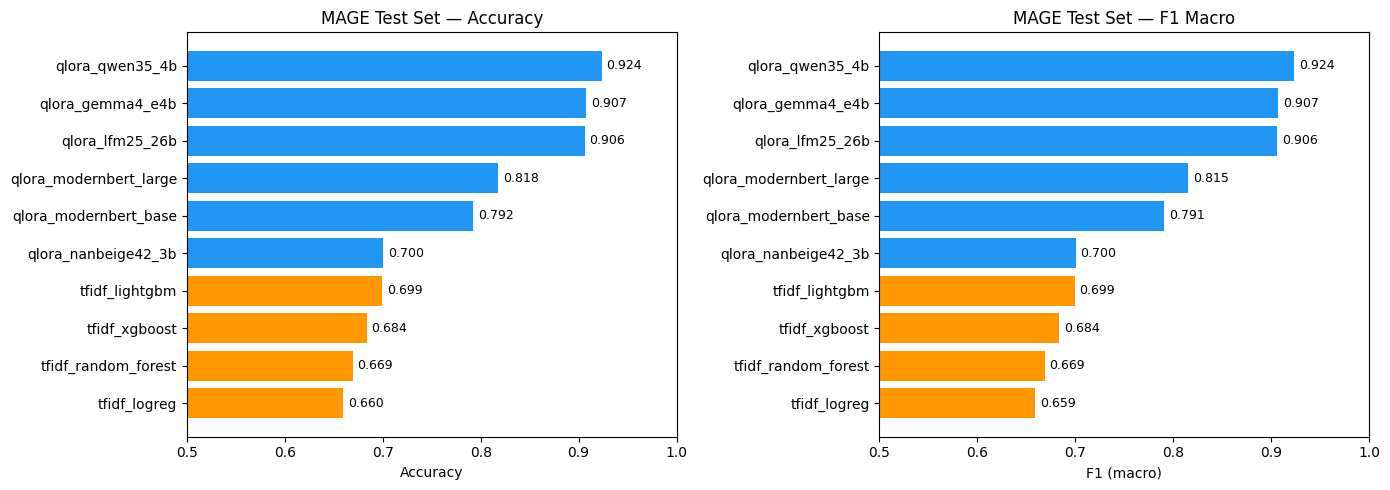

Saved: results/bench_aitextdetect_indomain.png


In [19]:
# --- Bar chart: In-domain test performance ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy
ax = axes[0]
df_plot = df_all_results.sort_values("accuracy", ascending=True)
colors = ["#2196F3" if "qlora" in m else "#FF9800" for m in df_plot["model"]]
ax.barh(df_plot["model"], df_plot["accuracy"], color=colors)
ax.set_xlabel("Accuracy")
ax.set_title("MAGE Test Set — Accuracy")
ax.set_xlim(0.5, 1.0)
for i, v in enumerate(df_plot["accuracy"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)

# F1 Macro
ax = axes[1]
df_plot = df_all_results.sort_values("f1_macro", ascending=True)
colors = ["#2196F3" if "qlora" in m else "#FF9800" for m in df_plot["model"]]
ax.barh(df_plot["model"], df_plot["f1_macro"], color=colors)
ax.set_xlabel("F1 (macro)")
ax.set_title("MAGE Test Set — F1 Macro")
ax.set_xlim(0.5, 1.0)
for i, v in enumerate(df_plot["f1_macro"]):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)

plt.tight_layout()
plt.savefig("results/bench_aitextdetect_indomain.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: results/bench_aitextdetect_indomain.png")

In [20]:
# --- Grouped bar chart: In-domain vs OOD generalisation ---
if ood_results:
    # Build a combined view: in-domain + each OOD split
    df_all_results_copy = df_all_results.copy()
    df_all_results_copy["dataset"] = "test (in-domain)"
    df_combined = pd.concat([df_all_results_copy, df_ood_all], ignore_index=True)

    models = df_combined["model"].unique()
    datasets = df_combined["dataset"].unique()
    n_datasets = len(datasets)

    fig, ax = plt.subplots(figsize=(14, 6))
    x = np.arange(len(models))
    width = 0.8 / n_datasets
    palette = ["#4CAF50", "#2196F3", "#FF5722", "#9C27B0"]

    for i, ds_name in enumerate(datasets):
        subset = df_combined[df_combined["dataset"] == ds_name]
        # Align by model order
        vals = []
        for m in models:
            row = subset[subset["model"] == m]
            vals.append(row["f1_macro"].values[0] if len(row) else 0)
        ax.bar(x + i * width, vals, width, label=ds_name, color=palette[i % len(palette)])

    ax.set_ylabel("F1 (macro)")
    ax.set_title("In-Domain vs OOD Generalisation — F1 Macro")
    ax.set_xticks(x + width * (n_datasets - 1) / 2)
    ax.set_xticklabels(models, rotation=30, ha="right")
    ax.legend()
    ax.set_ylim(0, 1.05)
    plt.tight_layout()
    plt.savefig("results/bench_aitextdetect_ood.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Saved: results/bench_aitextdetect_ood.png")

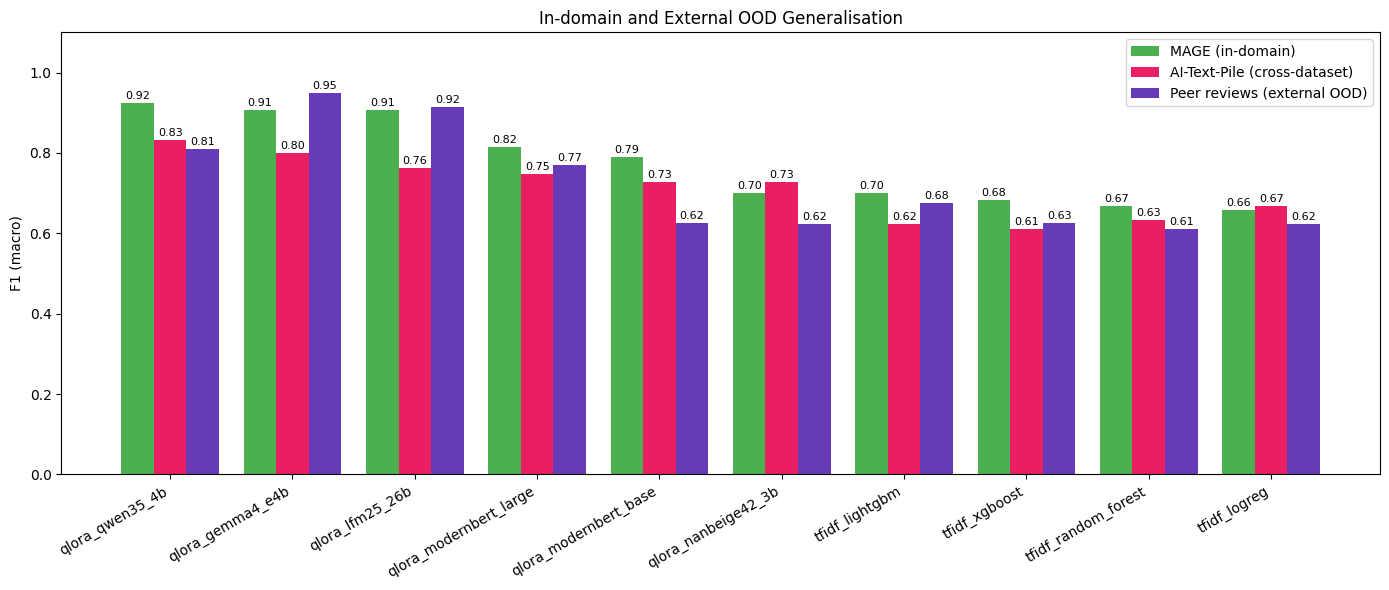

Saved: results/bench_aitextdetect_cross_dataset.png


In [21]:
# --- MAGE in-domain vs external OOD evaluations ---
df_mage = df_all_results.copy()
df_mage["dataset"] = "MAGE (in-domain)"
df_cross = df_pile_results.copy()
df_cross["dataset"] = "AI-Text-Pile (cross-dataset)"
df_external_ood_plot = df_external_ood_results.copy()
df_external_ood_plot["dataset"] = "Peer reviews (external OOD)"

df_cross_compare = pd.concat([df_mage, df_cross, df_external_ood_plot], ignore_index=True)

models_cross = df_cross_compare["model"].unique()
datasets_cross = ["MAGE (in-domain)", "AI-Text-Pile (cross-dataset)", "Peer reviews (external OOD)"]
x = np.arange(len(models_cross))
width = 0.8 / len(datasets_cross)

fig, ax = plt.subplots(figsize=(14, 6))
palette = ["#4CAF50", "#E91E63", "#673AB7"]

for i, ds_name in enumerate(datasets_cross):
    subset = df_cross_compare[df_cross_compare["dataset"] == ds_name]
    vals = []
    for m in models_cross:
        row = subset[subset["model"] == m]
        vals.append(row["f1_macro"].values[0] if len(row) else 0)
    bars = ax.bar(x + i * width, vals, width, label=ds_name, color=palette[i])
    for bar, v in zip(bars, vals):
        if v > 0:
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                    f"{v:.2f}", ha="center", va="bottom", fontsize=8)

ax.set_ylabel("F1 (macro)")
ax.set_title("In-domain and External OOD Generalisation")
ax.set_xticks(x + width * (len(datasets_cross) - 1) / 2)
ax.set_xticklabels(models_cross, rotation=30, ha="right")
ax.legend()
ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig("results/bench_aitextdetect_cross_dataset.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: results/bench_aitextdetect_cross_dataset.png")

## 11. Save Checkpoints Archive

In [22]:
import tarfile
from IPython.display import FileLink

results_path = "results/bench_aitextdetect"
if os.path.exists(results_path):
    archive_path = "results/bench_aitextdetect_checkpoints.tar.gz"
    with tarfile.open(archive_path, "w:gz") as tar:
        tar.add(results_path, arcname="bench_aitextdetect")
    print(f"Archive created: {archive_path}")
    FileLink(archive_path)
else:
    print("No results directory found — run training cells first.")

Archive created: results/bench_aitextdetect_checkpoints.tar.gz


## Analysis and Lessons Learned

Slurm job `1145971`. These measurements belong to this execution.

### MAGE test

| model | accuracy | f1_macro | roc_auc |
| --- | --- | --- | --- |
| qlora_qwen35_4b | 0.9236 | 0.9236 | 0.9776 |
| qlora_gemma4_e4b | 0.9075 | 0.9075 | 0.9660 |
| qlora_lfm25_26b | 0.9061 | 0.9061 | 0.9628 |
| qlora_modernbert_large | 0.8175 | 0.8153 | 0.9291 |
| qlora_modernbert_base | 0.7920 | 0.7908 | 0.8964 |
| qlora_nanbeige42_3b | 0.7004 | 0.7004 | 0.7799 |
| tfidf_lightgbm | 0.6994 | 0.6994 | 0.7813 |
| tfidf_xgboost | 0.6836 | 0.6836 | 0.7625 |
| tfidf_random_forest | 0.6691 | 0.6687 | 0.7390 |
| tfidf_logreg | 0.6596 | 0.6588 | 0.7295 |

The highest observed macro F1 is 0.9236, from `qlora_qwen35_4b`.

### Pile cross-dataset

| model | accuracy | f1_macro | roc_auc |
| --- | --- | --- | --- |
| qlora_qwen35_4b | 0.8310 | 0.8310 | 0.8984 |
| qlora_gemma4_e4b | 0.8042 | 0.8006 | 0.9294 |
| qlora_lfm25_26b | 0.7634 | 0.7633 | 0.8482 |
| qlora_modernbert_large | 0.7542 | 0.7473 | 0.8415 |
| qlora_modernbert_base | 0.7320 | 0.7282 | 0.8095 |
| qlora_nanbeige42_3b | 0.7274 | 0.7272 | 0.8033 |
| tfidf_logreg | 0.6672 | 0.6670 | 0.7276 |
| tfidf_random_forest | 0.6338 | 0.6321 | 0.6623 |
| tfidf_lightgbm | 0.6228 | 0.6228 | 0.6682 |
| tfidf_xgboost | 0.6110 | 0.6109 | 0.6512 |

The highest observed macro F1 is 0.8310, from `qlora_qwen35_4b`.

### Peer-review external OOD

| model | accuracy | f1_macro | roc_auc |
| --- | --- | --- | --- |
| qlora_gemma4_e4b | 0.9500 | 0.9499 | 0.9873 |
| qlora_lfm25_26b | 0.9155 | 0.9154 | 0.9776 |
| qlora_qwen35_4b | 0.8140 | 0.8093 | 0.9785 |
| qlora_modernbert_large | 0.7705 | 0.7700 | 0.8514 |
| tfidf_lightgbm | 0.6875 | 0.6757 | 0.7545 |
| tfidf_xgboost | 0.6315 | 0.6259 | 0.6526 |
| qlora_modernbert_base | 0.6455 | 0.6249 | 0.6942 |
| tfidf_logreg | 0.6265 | 0.6236 | 0.6742 |
| qlora_nanbeige42_3b | 0.6295 | 0.6223 | 0.6913 |
| tfidf_random_forest | 0.6425 | 0.6105 | 0.7605 |

The highest observed macro F1 is 0.9499, from `qlora_gemma4_e4b`.

Macro F1 weights the two classes equally. Compare each model across datasets: an external drop measures transfer on these samples, while a high random holdout score alone does not establish robustness to a new generator or acquisition pipeline. These are single-run comparisons without uncertainty intervals.

The peer-review evaluation combines a new domain with newer generators; it does not isolate a temporal effect. Detector scores are comparative signals, not calibrated authorship probabilities.
